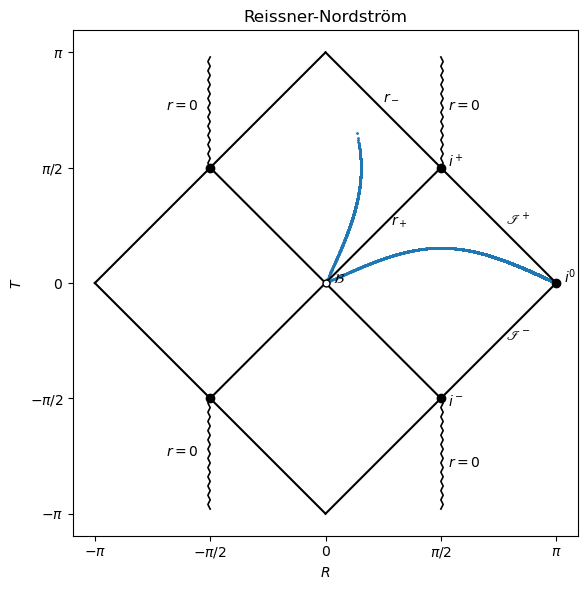

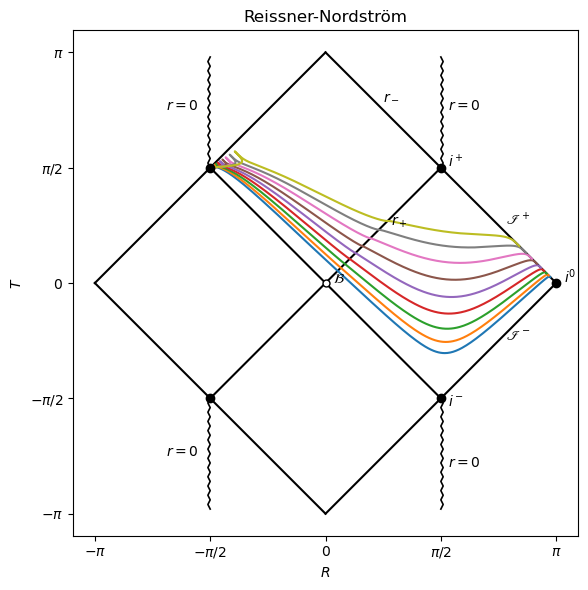

In [2]:
import numpy as np
import matplotlib.pyplot as plt

class Reissner_diagram:

    def _diag_init(self):
        scale = 6
        plt.figure(figsize=(scale, scale))
        
        # Forcing same scale on both axes
        ax = plt.gca()
        ax.set_aspect('equal', adjustable='box')

        # set ticks to pi
        ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
        tick_labels = [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$']

        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_xticklabels(tick_labels)
        ax.set_yticklabels(tick_labels)



        # y = x line
        x_line = np.array([-np.pi/2, np.pi/2])
        y_line = x_line
        plt.plot(x_line, y_line, lw=1.5, color='black')
        plt.plot(x_line - np.pi/2, y_line + np.pi/2, lw=1.5, color='black')
        plt.plot(x_line + np.pi/2, y_line - np.pi/2, lw=1.5, color='black')


        # line y = -x
        y_line2 = -x_line
        plt.plot(x_line, y_line2, lw=1.5, color='black')
        plt.plot(x_line + np.pi/2, y_line2 + np.pi/2, lw=1.5, color='black')
        plt.plot(x_line - np.pi/2, y_line2 - np.pi/2, lw=1.5, color='black')


        # zigzags
        x_start = np.pi/2
        y_start = np.pi/2
        y_end = np.pi
        x_end = x_start

        n_zigzags = 25
        width = (y_end - y_start)/n_zigzags
        


        y = np.array([y_start + l*width for l in range(n_zigzags)])
        x = np.array([x_start + (i % 2) * width/2 for i in range(n_zigzags)])
        l_width = 1.2
        plt.plot(x, y, lw=l_width, color='black')
        plt.plot(-x, y, lw=l_width, color='black')
        plt.plot(x, -y, lw=l_width, color='black')
        plt.plot(-x, -y, lw=l_width, color='black')

        margin = 0.3
        plt.xlim(-np.pi - margin, np.pi + margin)
        plt.ylim(-np.pi - margin, np.pi + margin)
        plt.xlabel(r'$R$')
        plt.ylabel(r'$T$')
        plt.title(r'Reissner-Nordström')
        plt.tight_layout()

    def _diag_markers(self):
        
        # Dots for  i-, i0, i+
        plt.plot(np.pi/2, np.pi/2, marker='o', color='black')
        plt.plot(-np.pi/2, -np.pi/2, marker='o', color='black')

        plt.plot(np.pi/2, -np.pi/2, marker='o', color='black')
        plt.plot(-np.pi/2, np.pi/2, marker='o', color='black')
        
        plt.plot(np.pi, 0, marker='o', color='black')
        

        # Bifurcation sphere
        plt.plot(0, 0, marker='o', markerfacecolor='white', markeredgecolor='black', markersize=5, linestyle='None')

        # denoting i-, i0, i+
        plt.text(np.pi/2 + 0.1, -np.pi/2 - 0.1, r'$i^-$')
        plt.text(np.pi + 0.1, 0, r'$i^0$')
        plt.text(np.pi/2 + 0.1, np.pi/2, r'$i^+$')

        # denoting r = 0
        plt.text(np.pi/2 + 0.1, 3*np.pi/4, r'$r = 0$')
        plt.text(np.pi/2 + 0.1, -3*np.pi/4 - 0.15, r'$r = 0$')
        plt.text(-np.pi/2 - 0.6, 3*np.pi/4, r'$r = 0$')
        plt.text(-np.pi/2 - 0.6, -3*np.pi/4, r'$r = 0$')

        # denoting r+-
        plt.text(np.pi/4 + 0.1, np.pi/4, r'$r_+$')
        plt.text( np.pi/4, 3*np.pi/4 + 0.14, r'$r_-$')
        # plt.text(np.pi/4, -np.pi/4, r'$r_-$')

        
        # plt.text(-np.pi/4 - 0.1, 3*np.pi/4 + 0.14, r'$\mathcal{C}^+_f$')

        # plt.text(np.pi/4, -3*np.pi/4 - 0.2, r'$\mathcal{C}^+_p$')


        # denoting scri
        plt.text(3*np.pi/4 + 0.1, np.pi/4, r'$\mathscr{I}^+$')
        plt.text(3*np.pi/4 + 0.1, -np.pi/4, r'$\mathscr{I}^-$')
        # denoting bifurcation sphere
        plt.text(0 + 0.1, 0, r'$\mathcal{B}$')

    def _add_to_show(self, T, R, color=None, label=None):
        # ensuring safe adding to show list
        self.to_show.append([T, R, color, label])
    def _safe_exp(self, x):
        return np.exp(np.clip(x, -50, 50))

    def _safe_log(self, x, eps=1e-12):
        x_safe = np.where(np.abs(x) < eps, eps, x)
        return np.log(x_safe)

    def _map_to_penrose(self, U, V, shift=False):

        U_comp = np.arctan(U)
        V_comp = np.arctan(V)

        T = U_comp + V_comp
        R = -U_comp + V_comp
        if shift:
            T += np.pi
            R -= np.pi
        return T, R

    def _height_fun(self, sigma, lamb=None, fixing_type='radial'):
        if lamb == None:
            lamb = self.rh
        kappa = self.kappa
        if fixing_type=='radial':
            term0 = -1/sigma
            term1 = (1 + kappa**2)*np.log(np.abs(sigma))
            term2 = 1/(1 - kappa**2)*(np.log(np.abs(1 - sigma)) - kappa**4*np.log(np.abs(1 - kappa**2*sigma)))
            rr = -1/sigma + term1 + term2
        elif fixing_type=='cauchy':
            K = (1 + kappa**2)*np.log(np.abs(1 - kappa**2)) + kappa**2
            term1 = (1 + kappa**2)*np.log(np.abs(sigma))
            term2 = np.log(np.abs(1 - sigma))/(1 - kappa**2)
            rr = -(1 - kappa**2)/sigma + term1 + term2 + K
        else:
            raise ValueError("Unexpected value of fixing_type while calling _height_fun")

        

        return rr
    


    #--------------------------#
    #--------------------------#
    ''' Initilizing function '''
    #--------------------------#
    #--------------------------#


    def __init__(self, M, Q):
        self.to_show = []
        if Q >= M:
            raise ValueError('Only Q < M case')
        self.M = M
        self.Q = Q
        epsilon = Q/M
        self.rh = M*(1 + np.sqrt(1 - epsilon**2))
        self.rc = M*(1 - np.sqrt(1 - epsilon**2))
        self.kappa = np.sqrt(self.rc/self.rh)
        

        # self._diag_init()
        # self._diag_markers()


    def _r_star(self, r):
        kappa = self.kappa
        rh = self.rh
        rr = rh/(1 - kappa**2)*(np.log(np.abs(r/rh - 1)) - kappa**4*np.log(np.abs(r/rh - kappa**2))) + r
        return rr

    def _r_star_from_hyp(self, sigma, fixing_type='radial'):
        if fixing_type == 'radial':
            rh = self.rh
            kappa = self.kappa
            
            term1 = -rh*(1 + kappa**2)*np.log(np.abs(sigma))
            term2 = rh/(1 - kappa**2)*(np.log(np.abs(1 - sigma)) - kappa**4*np.log(np.abs(1 - kappa**2*sigma)))
            rr = rh/sigma + term1 + term2
        elif fixing_type == 'cauchy':
            rh = self.rh
            kappa = self.kappa
            term0 = rh*(1 - kappa**2)/sigma
            term1 = rh*np.log(np.abs(1 - sigma))/(1 - kappa**2)
            term2 = -rh*(1 + kappa**2)*np.log(np.abs(sigma))
            term3 = rh*((1 + kappa**2)*np.log(np.abs(1 - kappa**2)) + kappa**2)
            rr = term0 + term1 + term2 + term3
        else:
            raise ValueError('meow meow')


        return rr
        
    


    def _u_v(self, t, r):
        r_star = self._r_star(r)
        u = t - r_star
        v = t + r_star
        return u, v
    
    def _u_v_from_hyp(self, tau, sigma, lamb, fixing_type='radial'):

        t = lamb*(tau - self._height_fun(sigma, lamb, fixing_type))

        rr = self._r_star_from_hyp(sigma, fixing_type)
        u = t - rr
        v = t + rr

        
        return u, v
        

    def _U_V(self, u, v, r):
        eps = 0.0001*self.rc
        mid_point = self.rc + eps

        # region_I = r > self.rp
        # region_IIa = (r < self.rp) & (r >= mid_point) 
        # region_IIb = (r < self.rp) & (r < mid_point) & (r > self.rm)
        # region_III = (r < self.rm)

        region_I = r > self.rh
        region_II = (r < self.rh) & (r > self.rc)
        region_III = (r < self.rc) & (r > 0)

        U = np.zeros_like(r)
        V = np.zeros_like(r)
        
        kp = 1/(2*self.rh*(1 + self.kappa**2))

        if np.any(region_I): # Using U+ V+ coordinates
            U[region_I] = -self._safe_exp(-kp*u[region_I])
            V[region_I] =  self._safe_exp( kp*v[region_I])

        if np.any(region_II): # Using U+ V+ with adjusted signs    
            U[region_II] = self._safe_exp(-kp*u[region_II])   
            V[region_II] = self._safe_exp( kp*v[region_II])

        # if np.any(region_IIb):      # Region II but close to the cauchy horizon
        #     U[region_IIb] = self._safe_exp(-km*u[region_IIb])
        #     V[region_IIb] = self._safe_exp( km*v[region_IIb])

        # if np.any(region_III):
        #     U[region_III] =  self._safe_exp(-km*u[region_III])
        #     V[region_III] = -self._safe_exp(+km*v[region_III])

        return U, V

    def _U_V_from_hyp(self, u, v, sigma, fixing_type='radial'):
        if fixing_type=='radial':
            regionI = sigma < 1     # Beyond rh horizon
            regionII = sigma >= 1    # under horizon




        elif fixing_type=='cauchy':
            regionI = sigma < 1     # Beyond rh horizon
            regionII = sigma >= 1    # under horizon
        
            
        else: 
            raise ValueError("Unexpected value of fixing_type while calling U_V function")
        U = np.empty_like(u)
        V = np.empty_like(v)
        rh = self.rh
        kappa = self.kappa
        U[regionI] = -self._safe_exp(-u[regionI]/(2*rh*(1 + kappa**2)))
        V[regionI] = self._safe_exp(v[regionI]/(2*rh*(1 + kappa**2)))

        U[regionII] = self._safe_exp(-u[regionII]/(2*rh*(1 + kappa**2)))
        V[regionII] = self._safe_exp(v[regionII]/(2*rh*(1 + kappa**2)))

        return U, V
    


    ####
    #### methods for adding curves
    ####
    def add_t_r_curve(self, t, r, color=None, label=None):
        u, v = self._u_v(t, r)
        U, V = self._U_V(u, v, r)
        T, R = self._map_to_penrose(U, V)

        self._add_to_show(T, R, color, label) 

    def add_tau_sigma(self, tau, sigma, lamb=None, fixing_type='radial', color=None, label=None):
        if lamb == None:
            lamb = self.rh

        u, v = self._u_v_from_hyp(tau, sigma, lamb, fixing_type)

        
        U, V = self._U_V_from_hyp(u, v, sigma, fixing_type)

        T, R = self._map_to_penrose(U, V)
        self._add_to_show(T, R, color, label)
        
        # self.add_t_r_curve(t, r, color, label)
        


    def show(self, scatter=False, marker_size=1):
        self._diag_init()

        for T, R, cl, label in self.to_show:
            if scatter==False:
                if cl != None and label != None:
                    plt.plot(R, T, color=cl, label=label)
                elif cl != None:
                    plt.plot(R, T, color=cl)
                elif label != None:
                    plt.plot(R, T, label=label)
                else:
                    plt.plot(R, T)
            else:
                if cl != None and label != None:
                    plt.scatter(R, T, color=cl, label=label, s=marker_size)
                elif cl != None:
                    plt.scatter(R, T, color=cl, s=marker_size)
                elif label != None:
                    plt.scatter(R, T, label=label, s=marker_size)
                else:
                    plt.scatter(R, T, s=marker_size)

        self._diag_markers()
        # show legend only if any non-empty label present
        if any((lbl is not None and lbl != '') for _, _, _, lbl in self.to_show):
            plt.legend()
        plt.show()

test = Reissner_diagram(1, 0.9)

r = np.linspace(0, 400, 500001)
t = 2

test.add_t_r_curve(t, r)
test.show(scatter=True)

sigma_i = 10**(-6)
taus_values = np.arange(-7, -1, 2/3)
sigma = np.linspace(sigma_i, 50, 10000)
rh = 1
diag = Reissner_diagram(1, 0.9)

for val in taus_values:
    tau = val*np.ones_like(sigma)
    diag.add_tau_sigma(tau, sigma, fixing_type='radial')
diag.show()

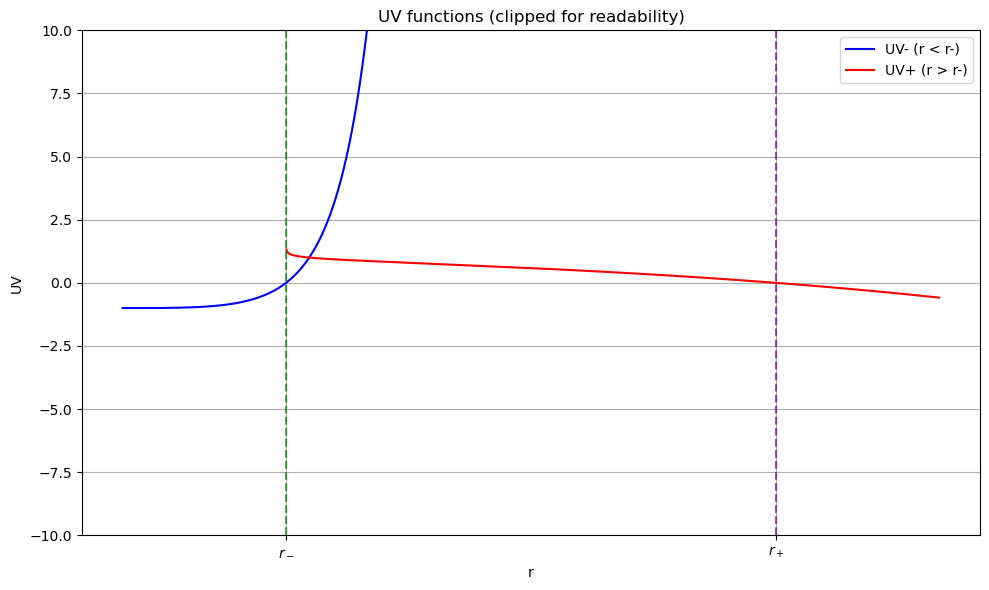

rp = 1.5999999999999999, rm = 0.40000000000000013


In [3]:

eps = 0.8
rh = 1 + np.sqrt(1 - eps**2)
rc = 1 - np.sqrt(1 - eps**2)

kp = (rh - rc)/(2*rh**2)
km = (rc - rh)/(2*rc**2)

def UV_p(r):
    return -np.exp(2*kp*r)*(r - rh)/rh * (rc/(r - rc))**(np.abs(kp/km))

def UV_m(r):
    return np.exp(2*km*r)*(r - rc)/rc * (-rh/(r - rh))**(np.abs(km/kp))

# --- Avoid singularities ---
delta = 1e-3  # small cutoff distance

r_low = np.linspace(0, rh - delta, 5000)
r_high = np.linspace(rc + delta, 2, 5000)

UV_m_arr = UV_m(r_low)
UV_p_arr = UV_p(r_high)

# --- Clip extreme values ---
clip_val = 10  # adjust depending on how much detail you want

UV_m_arr = np.where(np.abs(UV_m_arr) > clip_val, np.nan, UV_m_arr)
UV_p_arr = np.where(np.abs(UV_p_arr) > clip_val, np.nan, UV_p_arr)

# --- Plot ---
plt.figure(figsize=(10, 6))

plt.plot(r_low, UV_m_arr, 'b-', label='UV- (r < r-)')
plt.plot(r_high, UV_p_arr, 'r-', label='UV+ (r > r-)')

plt.axvline(x=rc, color='green', linestyle='--', alpha=0.7)
plt.axvline(x=rh, color='purple', linestyle='--', alpha=0.7)

plt.xlabel('r')
plt.ylabel('UV')
plt.title('UV functions (clipped for readability)')
plt.legend()
plt.grid(True)

plt.xticks([rc, rh], [r'$r_-$', r'$r_+$'])

plt.ylim(-clip_val, clip_val)

plt.tight_layout()
plt.show()

print(f"rp = {rh}, rm = {rc}")